In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


#  Pourquoi utiliser Pickle pour sauvegarder le dataset préprocessé ?
**1. CONSERVATION DES TYPES**

Pickle ne sauvegarde pas uniquement les valeurs, mais aussi le type de chaque objet (numpy arrays, tenseurs, listes, etc.), contrairement à JSON et CSV qui perdent les types complexes.

**2. SUPPORT D'OBJETS COMPLEXES**

JSON et CSV ne peuvent pas stocker des structures comme :

- numpy arrays (avec dtype, shape, etc.)
- Tenseurs PyTorch / TensorFlow
- Objets Python personnalisés

**3. RAPIDITÉ ET MODULARITÉ**

Le preprocessing peut être long (nettoyage, encodage, normalisation...).

En sauvegardant le résultat dans des fichiers Pickle, on évite de refaire cette étape à chaque fois.
Pour entraîner le modèle, il suffit de charger directement les fichiers Pickle et de passer à l'étape suivante.

In [2]:
import pickle
import os

# Chemin de base vers le dossier contenant les fichiers Pickle préprocessés
base_path = "/content/drive/MyDrive/emotion-detection/data/processed"

def get_pickle_file(name_file) :
  with open(os.path.join(base_path ,name_file) , "rb") as f :
      return pickle.load(f)


In [3]:
# ============================================================
# Chargement des données préprocessées depuis les fichiers Pickle
# ============================================================

# --- Données d'entraînement ---
X_train = get_pickle_file("X_train.pkl")
Y_train = get_pickle_file("Y_train.pkl")

# --- Données de validation ---
X_val = get_pickle_file("X_val.pkl")
Y_val = get_pickle_file("Y_val.pkl")

# --- Données de test ---
X_test = get_pickle_file("X_test.pkl")
Y_test = get_pickle_file("Y_test.pkl")

In [4]:
# ============================================================
# Vérification des shapes
# ============================================================
datasets = {
    "Train"      : (X_train, Y_train),
    "Validation" : (X_val,   Y_val),
    "Test"       : (X_test,  Y_test),
}

for split, (X, Y) in datasets.items():
    print(f"[{split}]  X : {X.shape}  |  Y : {Y.shape}")

[Train]  X : (28709, 48, 48, 1)  |  Y : (28709, 7)
[Validation]  X : (3589, 48, 48, 1)  |  Y : (3589, 7)
[Test]  X : (3589, 48, 48, 1)  |  Y : (3589, 7)


In [5]:
# Récupération d'une image
import matplotlib.pyplot as plt

image = X_train[2].reshape(48,48)
emotion = Y_train[2]

In [6]:
# Emotion affecté : Fear( peur )
print(emotion)

[0. 0. 1. 0. 0. 0. 0.]


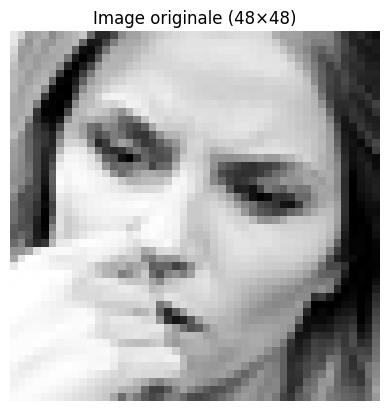

In [7]:
plt.imshow(image, cmap='gray' )
plt.title("Image originale (48×48)")
plt.axis("off")
plt.show()

In [8]:
import numpy as np
filtres = {
    "Contours verticaux": np.array([
        [-1,  0,  1],
        [-1,  0,  1],
        [-1,  0,  1]
    ], dtype=np.float32),

    "Contours horizontaux": np.array([
        [ 1,  1,  1],
        [ 0,  0,  0],
        [-1, -1, -1]
    ], dtype=np.float32),

    "Diagonales": np.array([
        [-1,  0,  1],
        [ 0,  0,  0],
        [ 1,  0, -1]
    ], dtype=np.float32),

    "Détection de coins (Laplacien)": np.array([
        [ 0, -1,  0],
        [-1,  4, -1],
        [ 0, -1,  0]
    ], dtype=np.float32),
}

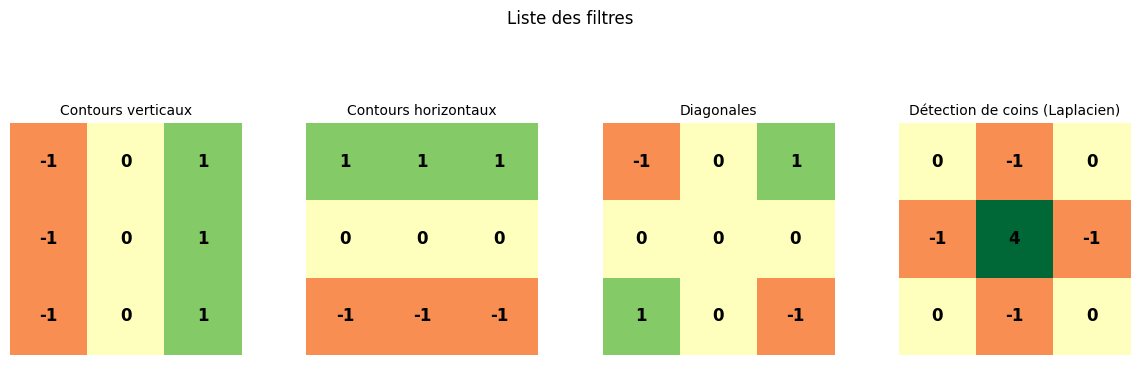

In [9]:
# On crée une figure avec 1 ligne et 4 colonnes de sous-graphiques -- un subplot par filtre.
# figsize(12 , 3) définit la taille en pouces(largeur , hauteur )
fig, axes = plt.subplots(1 , 4 , figsize = (12 ,3))

# filtres.item() : retourne des paires (clé , valeur) -- ici (nom , matrice 3*3 )
# zip(axes , filtres.item() ) : associe chaque axe avec son filtre correspondant
for ax , (nom , filtre) in zip(axes , filtres.items()) :
  # imshow affiche une matrice comme une image, chaque case devient un pixel coloré
  # vmin=-2, vmax=2 : fixe les bornes de la colormap : -2 sera rouge foncé, 0 sera jaune, +2 sera vert foncé

  ax.imshow(filtre, cmap="RdYlGn", vmin=-2, vmax=2)

  ax.set_title(nom, fontsize=10)

  # Ecrire les valeurs dans chaque colonne :
  for i in range(3) :
    for j in range(3) :
      ax.text(j , i , f"{filtre[i,j]:.0f}" , ha="center", va="center",
                fontsize=12, fontweight="bold",
                color="black")
  ax.axis("off")
plt.suptitle("Liste des filtres", y=1.2)
plt.tight_layout()
plt.show()


In [10]:
from scipy.signal import convolve2d

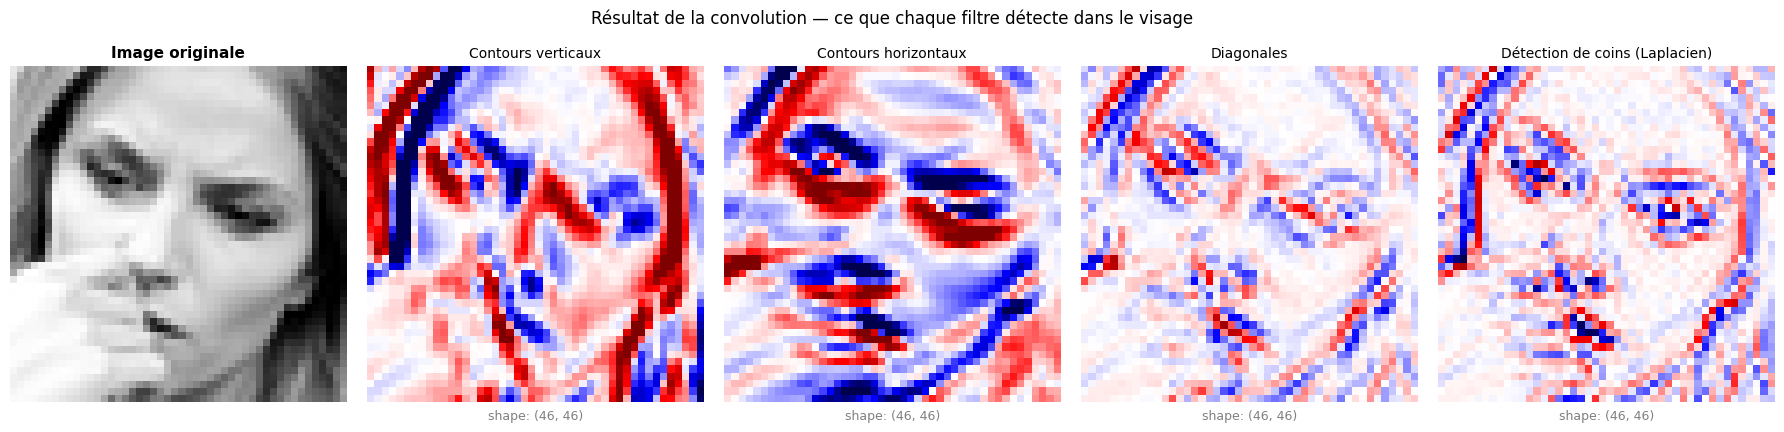

In [11]:
feature_maps = {}

for nom, filtre in filtres.items():
    # convolve2d applique le filtre sur toute l'image
    fm = convolve2d(image, filtre,  mode="valid")
    feature_maps[nom] = fm

# Visualisation : image originale + 4 feature maps
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
axes[0].imshow(image, cmap="gray")
axes[0].set_title("Image originale", fontsize=11, fontweight="bold")
axes[0].axis("off")

for ax, (nom, fm) in zip(axes[1:], feature_maps.items()):
    # seismic est une colormap divergente centrée sur 0 :
     # valeurs négatives -> bleu foncé
     # 0 -> blanc
     # valeurs positives -> rouge foncé
    ax.imshow(fm, cmap="seismic", vmin=-1, vmax=1)
    ax.set_title(nom, fontsize=10)
    # Afficher la forme
    ax.axis("off")
    ax.text(0.5, -0.05, f"shape: {fm.shape}",
        transform=ax.transAxes, # Coordonnées relatives au subplot
        ha="center", fontsize=9,
        color="gray")
plt.suptitle("Résultat de la convolution — ce que chaque filtre détecte dans le visage", y=1.02)
plt.tight_layout()
plt.show()

In [12]:
from skimage.measure import block_reduce

def relu(x):
    # Supprime toutes les valeurs négatives — garde uniquement les activations positives
    return np.maximum(0, x)

def maxpool2x2(x):
    # Divise la feature map en blocs 2x2 et garde la valeur maximale
    # block_reduce fait exactement ça avec np.max comme fonction d'agrégation
    return block_reduce(x, block_size=(2, 2), func=np.max)

In [13]:
fm_exemple = feature_maps["Contours verticaux"]
fm_relu    = relu(fm_exemple)
fm_pool    = maxpool2x2(fm_relu)


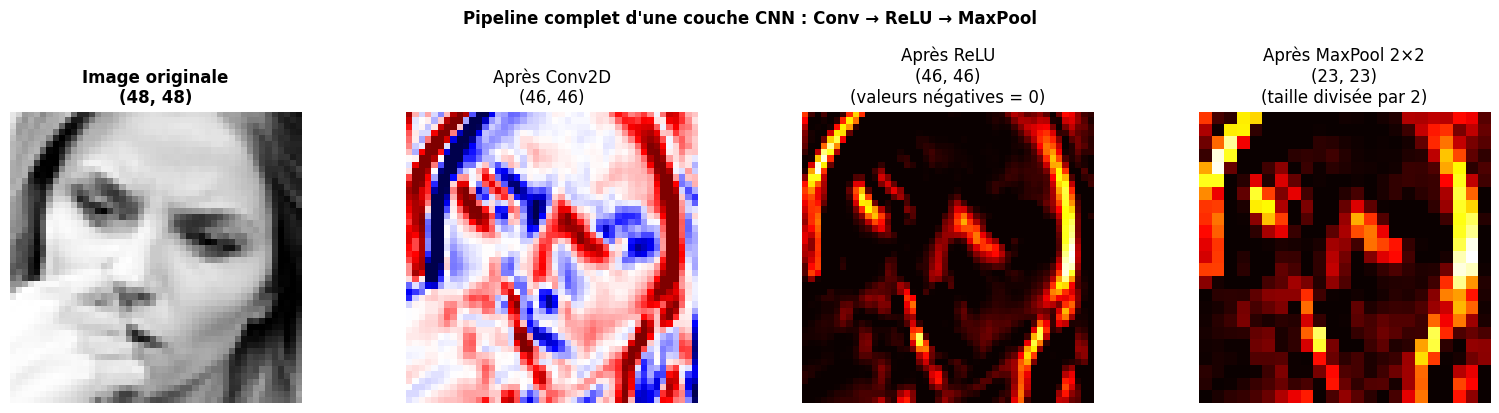

Réduction de taille : (48, 48) → (23, 23)
Nombre de valeurs : 2304 → 529 (23%)


In [14]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(image, cmap="gray")
axes[0].set_title(f"Image originale\n{image.shape}", fontweight="bold")
axes[0].axis("off")

axes[1].imshow(fm_exemple, cmap="seismic", vmin=-1, vmax=1)
axes[1].set_title(f"Après Conv2D\n{fm_exemple.shape}")
axes[1].axis("off")
# "hot" est une color map séquentielle :
 #  0   →   0.25      →   0.5  →  0.75 →   1
 # noir → rouge foncé → orange → jaune → blanc
axes[2].imshow(fm_relu, cmap="hot")
axes[2].set_title(f"Après ReLU\n{fm_relu.shape}\n(valeurs négatives = 0)")
axes[2].axis("off")

axes[3].imshow(fm_pool,cmap="hot")
axes[3].set_title(f"Après MaxPool 2×2\n{fm_pool.shape}\n(taille divisée par 2)")
axes[3].axis("off")

plt.suptitle("Pipeline complet d'une couche CNN : Conv → ReLU → MaxPool", y=1.02, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"Réduction de taille : {image.shape} → {fm_pool.shape}")
print(f"Nombre de valeurs : {image.size} → {fm_pool.size} ({fm_pool.size/image.size*100:.0f}%)")

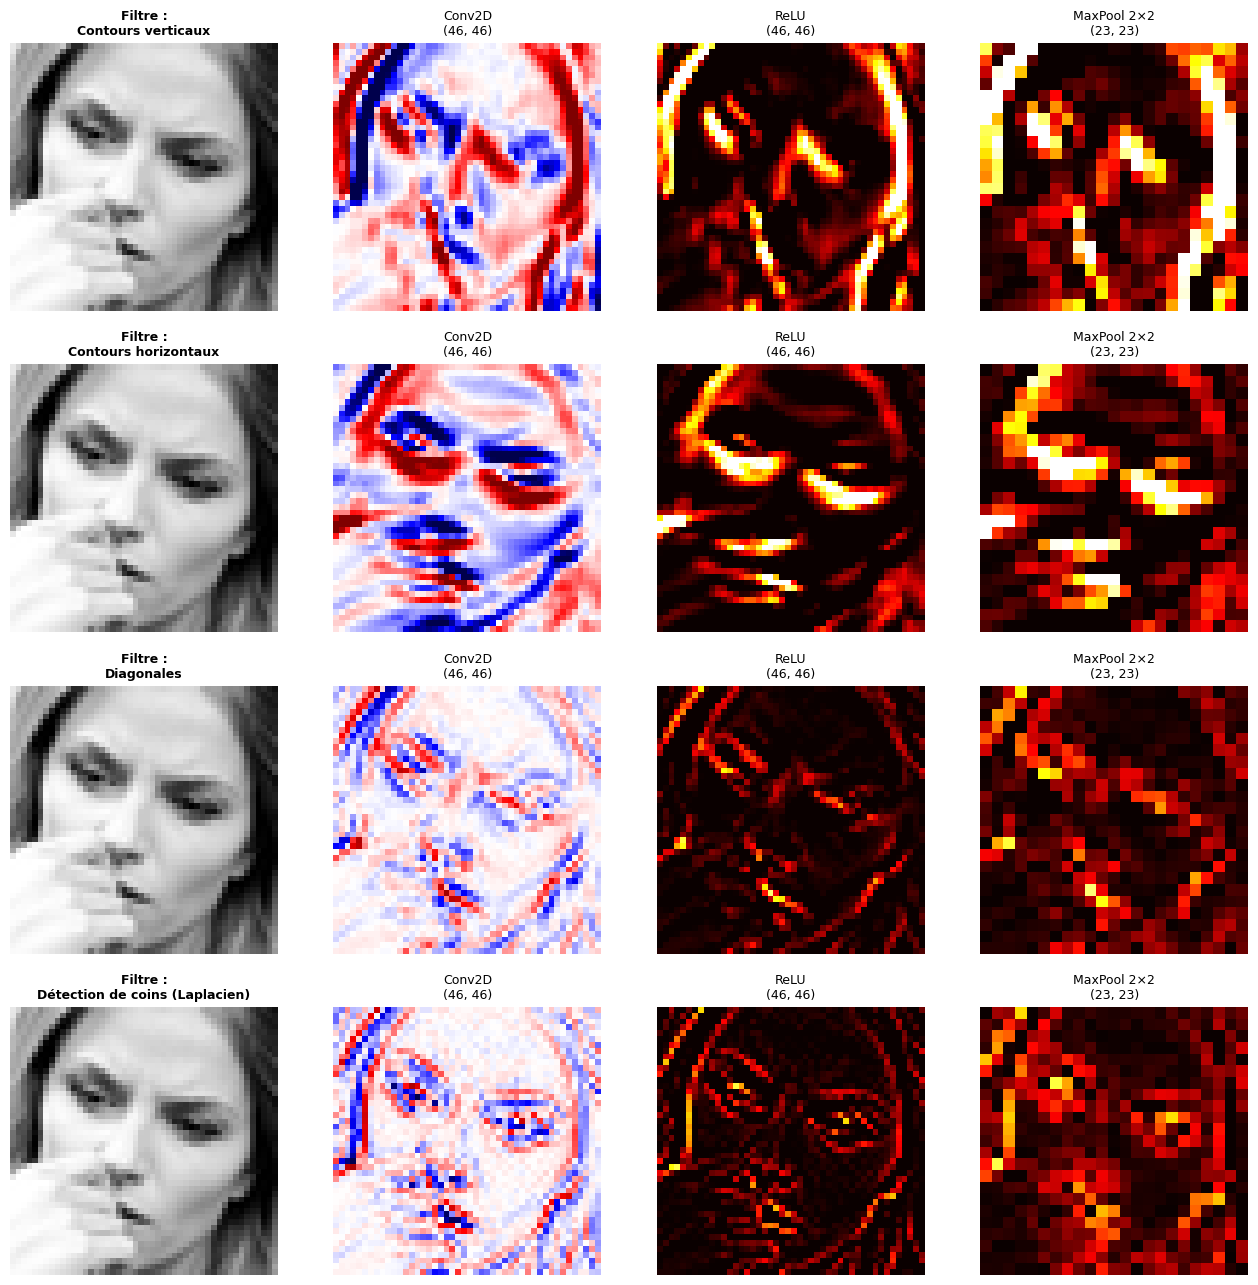

In [15]:
fig, axes = plt.subplots(4, 4, figsize=(16, 16))
etapes = ["Conv2D", "ReLU", "MaxPool 2×2"]

for row, (nom, filtre) in enumerate(filtres.items()):
    fm    = convolve2d(image, filtre, mode="valid")
    fm_r  = relu(fm)
    fm_p  = maxpool2x2(fm_r)

    resultats = [fm, fm_r, fm_p]
    cmaps     = ["seismic", "hot", "hot"]
    vmins     = [-1, 0, 0]
    vmaxs     = [ 1, 1, 1]

    # Colonne 0 : nom du filtre
    axes[row][0].imshow(image, cmap="gray")
    axes[row][0].set_title(f"Filtre :\n{nom}", fontsize=9, fontweight="bold")
    axes[row][0].axis("off")

    for col, (res, cmap, vmin, vmax, etape) in enumerate(zip(resultats, cmaps, vmins, vmaxs, etapes)):
      axes[row][col+1].imshow(res, cmap=cmap, vmin=vmin, vmax=vmax)
      axes[row][col+1].set_title(f"{etape}\n{res.shape}", fontsize=9)
      axes[row][col+1].axis("off")


# Pourquoi un CNN et pas un MLP pour les images ?

## Le MLP explose en nombre de paramètres
###Démonstration :
Chaque entrée est liée à chaque neurone de la couche cachée. Avec une image de 48×48 et une couche cachée de 512 neurones :

2304 pixels × 512 neurones = 1 179 648 poids,
seulement pour la première couche

Et chacun de ces poids est totalement idépendant. Le poids qui lie le pixel (10,10) au neurone 5 n'a aucun lien avec le poids qui lie le pixel (10,11) au neurone 5 — même si ces deux pixels sont voisins et font partie du même contour d'œil. Le modèle doit donc apprendre séparement l'importance de chaque pixel pour chaque neurone.
###Solution CNN :
Un filtre 3×3 = 9 poids seulement. Et ces 9 poids sont partagés sur toute l'image — le meme filtre glisse partout. Si ce filtre apprend à détecter un contour d'oeil à la position (10,10).

Il détecte automatiquement ce même contour à la position (30,20) sans réapprendre.

MLP  : 1 179 648 poids  (première couche uniquement)

CNN  : 9 poids × 32 filtres = 288 poids

La réduction est massive — et sans perte d'information utile.




## L'invariance à la translation
### Problématique :
Imaginons qu'on entraîne un modèle sur ces deux images d'un sourire :
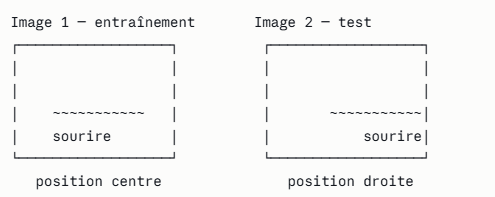

Pour un MLP, ces deux images sont fondamentalement différentes. Voici pourquoi :

Après aplatissement, le sourire en position centre occupe les indices 1100 → 1150 dans le vecteur. Le sourire en position droite occupe les indices 1160 → 1210.

Ce sont des pixels différents à des positions différentes dans le vecteur — le modèle reçoit donc un signal complètement différent pour le même pattern.

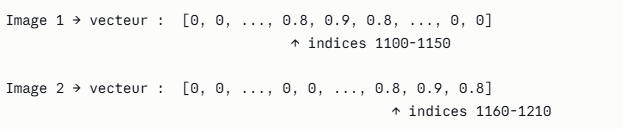

Le MLP a appris que les indices 1100-1150 correspondent à un sourire — mais quand le sourire apparaît aux indices 1160-1210 il ne reconnaît rien. Pour qu'il généralise, il faudrait lui montrer ce sourire à toutes les positions possibles pendant l'entraînement :

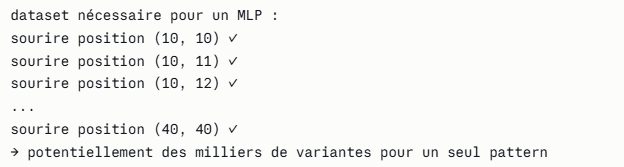

### Solution CNN — l'invariance à la translation par construction
Le CNN résout ce problème non pas pendant l'entraînement, mais dans son architecture même. Un filtre ne s'applique pas à une position fixe — il glisse sur toute l'image :


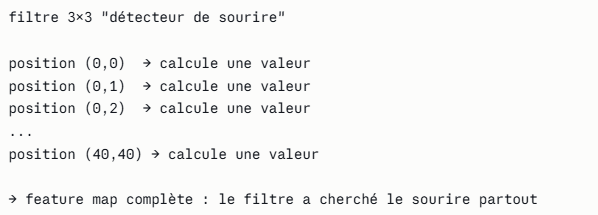

Les mêmes 9 poids ont analysé chaque zone de l'image. Donc si ces 9 poids ont appris à reconnaître un sourire, ils le reconnaissent automatiquement à n'importe quelle position — sans avoir besoin de le réapprendre.

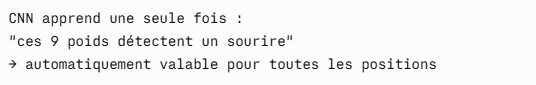

## La contrainte comme force — CNN vs MLP
### L'intuition centrale
On pourrait penser qu'un modèle avec plus de liberté apprend mieux. C'est l'inverse qui est vrai.
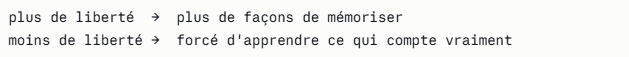

### Du polynôme aux images — généralisation

On a 2 points d'entraînement et un polynôme de degré 5 :

 * points d'entraînement :  (2, 4)  et  (6, 8)
* vraie relation          :  y = 2x  (une droite simple)

Le polynôme de degré 5 a 6 coefficients à ajuster pour seulement 2 contraintes — système sous-déterminé. Il trouve une infinité de solutions qui donnent erreur = 0 sur les 2 points. Parmi toutes ces solutions, il choisit la plus accessible depuis l'initialisation aléatoire — une courbe complexe qui zigzague entre les points. Sur un nouveau point jamais vu, cette courbe donne une valeur complètement fausse.

* degré 1  →  2 coefficients, 2 contraintes  →  1 seule solution  →  généralise

* degré 5  →  6 coefficients, 2 contraintes  →  ∞ solutions        →  mémorise

### Généralisation au MLP sur les images

C'est exactement le même problème à une échelle massive :
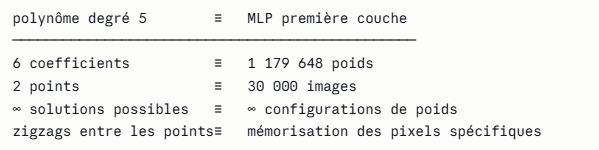

Le MLP a 1 179 648 poids pour seulement 30 000 images. Exactement comme le polynôme de degré 5 avec 2 points — le système est massivement sous-déterminé. Il existe une infinité de configurations de poids qui donnent une erreur nulle sur les 30 000 images d'entraînement.

La descente de gradient part d'une initialisation aléatoire et trouve la solution la plus accessible — celle qui mémorise des détails spécifiques :

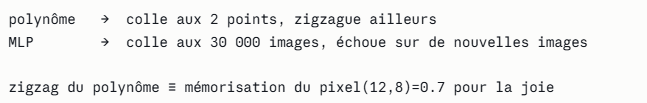

Sur une nouvelle image de joie où ce pixel vaut 0.6 — le MLP échoue exactement comme le polynôme échoue sur un nouveau point qui tombe dans un zigzag.

### Généralisation au CNN sur les images


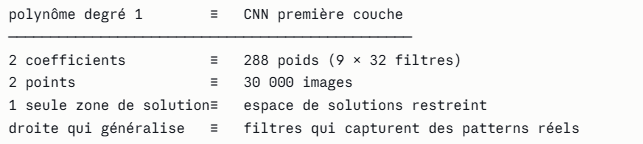

Avec seulement 288 poids pour 30 000 images — le système est sur-déterminé. Il y a beaucoup plus de contraintes que de paramètres. Le modèle ne peut pas se permettre de mémoriser des pixels spécifiques — ses 9 poids par filtre doivent fonctionner sur toute l'image, sur tous les visages, dans toutes les conditions.

* droite forcée à passer   →  capture la vraie relation y = 2x
  près de tous les points

* filtre CNN forcé à       →  capture le vrai pattern
  fonctionner partout       "courbe vers le haut = sourire"

# Pourquoi le Data Augmentation


## Forcer le modèle à apprendre des patterns stables et non mémoriser
Sans augmentation, le modèle a une liberté totale pour mémoriser des coïncidences spécifiques à chaque image. Avec augmentation, il reçoit le même label pour des versions différentes de la même image :
* image originale   →  label = "happy"
* même image rotée  →  label = "happy"
* même image flippée →  label = "happy"

La descente de gradient essaie de trouver des poids qui minimisent la loss sur toutes ces versions simultanément. Les poids liés à des pixels spécifiques sont corrigés dans tous les sens à chaque epoch — ils convergent vers zéro parce qu'ils ne sont pas stables. Seuls les poids qui capturent quelque chose de commun à toutes les versions survivent :

* ce qui change    →  position, luminosité, orientation
                    → poids instables → convergent vers 0

* ce qui reste     →  la structure du sourire, la forme des sourcils
                    → poids stables → renforcés

## Augmenter artificiellement la taille du dataset

FER2013 a des classes très déséquilibrées :
* happy   : 8 000 images   ← sur-représentée
* disgust :   547 images   ← sous-représentée

Avec 547 images de disgust, le modèle voit trop peu d'exemples pour apprendre les patterns de cette classe, — il va naturellement biaiser ses prédictions vers happy. La data augmentation génère de nouvelles versions pour les classes minoritaires :

547 images disgust × 5 transformations = 2 735 exemples
* le déséquilibre est réduit
* le modèle apprend mieux les classes rares

## Améliorer la robustesse aux conditions réelles
Dans la réalité, les visages ne sont jamais dans des conditions parfaites — éclairage variable, légère inclinaison, caméra de mauvaise qualité. Si le modèle n'a été entraîné que sur des images propres et bien cadrées, il échoue dès qu'une condition change légèrement.

sans augmentation :
* entraîné sur   →  visages bien éclairés, centrés, droits
* testé sur      →  visage légèrement sombre, décalé, incliné
* résultat       →  échec — le modèle n'a jamais vu ça

avec augmentation :
* entraîné sur   →  variations de luminosité, rotations, décalages
* testé sur      →  visage légèrement sombre, décalé, incliné
* résultat       →  succès — le modèle a appris à gérer ces variations

Chaque transformation simule une condition réelle que le modèle va forcément rencontrer en déploiement.

##  Renforcer l'invariance à la translation apprise par le CNN

Le CNN a déjà une invariance partielle à la translation grâce au glissement des filtres. Mais cette invariance a des limites — un grand décalage ou une rotation importante peut toujours tromper le modèle. La data augmentation renforce et étend cette invariance :
* CNN seul         →  invariance locale aux petites translations
* CNN + augmentation →  invariance étendue aux grandes translations,
                       rotations, changements d'échelle

C'est une synergie — l'architecture CNN et la data augmentation se complètent pour construire une invariance plus robuste que l'une ou l'autre seule.

## Réduire l'overfitting sans réduire la capacité du modèle

Les solutions classiques contre l'overfitting comme le Dropout ou la régularisation L2 réduisent la capacité du modèle — ils le rendent moins puissant pour éviter la mémorisation. La data augmentation résout le problème différemment — elle augmente les contraintes sans toucher à l'architecture :

* Dropout          →  réduit la capacité  →  moins de mémorisation
                                            mais aussi moins de puissance

* Data augmentation →  augmente les contraintes → moins de mémorisation
                                                capacité préservée

###**Filp Horizontal**

Un visage vu de gauche ou de droite exprime la meme emotion. C'est l'augmentation la plus naturelle pour les visages.

**Params :** Aucun paramètre à ajuster — activer/désactiver seulement.

**Effet :** Double la taille effective du dataset.

### **Rotation légère**
Simule les variations de pose de tête(légèrement inclinée). Au-delà de 15°, le visage devient peu naturel et peut confondre le modèle.

**Params :** Garder entre 8° et 15° max. Au-delà, les traits faciaux sont trop déformés.

**Effet :** Améliore la robustesse aux légères inclinaisons de tête.

### **Zoom / crop aléatoire**
Simule les distances différentes entre le visage et le caméra (gros plan vs plan éloigné). Aide aussi à marquer les coins non-pertinents.

**Params :** Limiter à ±10-15%. Un zoom excessif coupe les traits du visage (yeux, bouche).

**Effet :** Robustesse aux variations de distance caméra-visage.

### **Variation de luminosité**
Simule les conditions d'éclairage différentes (intérieur, plein soleil, sombre). Très courant en conditions réelles.

* 0 =  noir total (toute la lumière supprimée)
* 0.7 = % de la luminosité originale → légèrement sombre
* 1.0 = image originale, inchangée
* 1.3 = 130% de la luminosité originale → légèrement surexposée
* 2.0 = double de la luminosité → très surexposée, presque blanche



**Params :** Plage recommandée : [0.6, 1.4], éviter [0.1, 2.0] car trop extrême.

**Effet :**  Améliore fortement la généralisation en conditions d'éclairage variées.

### **Translation**
Simule un visage non centré dans l'image, légèrement décalé. Utile si le détecteur du visage n'est pas parfaitement centré.

**Params :** Max 10% de décalage. Au-delà, des parties du visage sortent du cadre.

**Effet :** Robustesse aux erreurs de détection et recadrage du visage.

### **Bruit gaussien**
Simule le bruit de capteur photo, surtout en basse lumière. Rend le modèle plus robuste aux images de mauvaise qualité

**Params :**  Variance faible (5–25). Un bruit trop fort masque les micro-expressions.

**Effet :** Robustesse aux images basse qualité / basse résolution.

In [16]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator



datagen_train = ImageDataGenerator(
    # Essentiel
    horizontal_flip = True  ,

    # Haute priorité
    rotation_range = 10 ,
    zoom_range = 0.10 ,

    # Priorité moyenne
    width_shift_range=0.08,
    height_shift_range=0.08,

    # après rotation/translation, les coins de l'image deviennent vides
    # fill_mode='nearest' les remplit avec la valeur du pixel voisin le plus proche
    fill_mode='nearest'
)

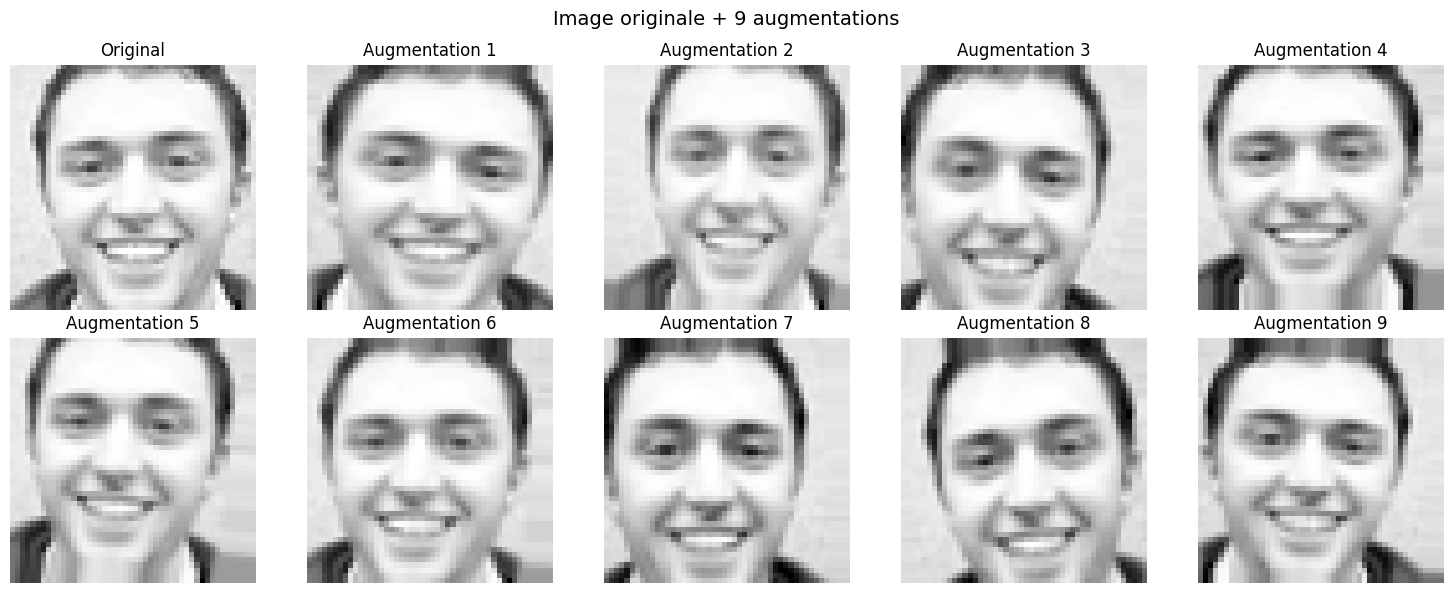

In [17]:
# Affichage
import matplotlib.pyplot as plt , numpy as np

image =np.expand_dims(X_train[30], axis=0) # dimension batch : (1, 48, 48, 1)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

# image originale
axes[0].imshow(image.squeeze(), cmap='gray')
axes[0].set_title('Original')
axes[0].axis('off')

# 9 versions augmentées
for i, batch in enumerate(datagen_train.flow(image, batch_size=1)):
    if i == 9:
        break
    axes[i+1].imshow(batch[0].squeeze(), cmap='gray')
    axes[i+1].set_title(f'Augmentation {i+1}')
    axes[i+1].axis('off')

plt.suptitle('Image originale + 9 augmentations', fontsize=14)
plt.tight_layout()
plt.show()

# Réseau de Neurones Convolutif (CNN) pour la Détection des Émotions




## 1. Intuition générale
Le CNN est une architecture conçue spéccialement pour le computer vision.
Contrairement à un réseau classique qui traiterait l'image en un seul bloc,
le CNN s'inspire du fonctionnement du cerveau visuel humain : il ne reconnaît
pas un visage d'un seul coup, mais combine progressivement des informations
de plus en plus abstraites pour arriver à une décision.

La hiérarchie de reconnaissance suit cette logique :
- couche 1 → détecte les bordures et contours
- couche 2 → combine les bordures pour détecter des formes
- couche 3 → combine les formes pour détecter des parties du visage (yeux, bouche, nez)
- couche 4 → combine les parties pour détecter des expressions


## 2. Le filtre convolutif
Un filtre est une petite matrice (ex: 3x3) dont les valeurs sont les poids
du réseau. Ces poids sont initialisés aléatoirement au départ, puis ajustés
automatiquement pendant l'entraînement.

Le filtre glisse sur toute l'image (stride), et à chaque position il effectue
une multiplication entre ses poids et les pixels couverts, puis fait la somme
de tous ces produits. Ce résultat mesure à quel point le pattern du filtre
est présent dans cette région de l'image.

Un même filtre appliqué sur toute l'image produit une **feature map** :
une carte qui indique où ce pattern a été détecté et avec quelle intensité.

Avec 32 filtres dans la première couche, on obtient 32 feature maps,
chacune spécialisée dans la détection d'un pattern différent.

## 3. ReLU (Rectified Linear Unit)
Après la convolution, chaque valeur de la feature map peut être :
- **positive** : le filtre a détecté son pattern dans cette région
- **négative** : le filtre n'a rien trouvé d'intéressant

ReLU applique une règle simple :
- valeur positive → conservée telle quelle
- valeur négative → remplacée par 0

Cela permet de ne conserver que les détections positives et d'introduire
de la non-linéarité dans le réseau, ce qui lui permet d'apprendre
des patterns complexes.



## 4. MaxPooling
Après ReLU, la feature map indique où les patterns ont été détectés.
MaxPooling divise cette feature map en petites régions (ex: 2x2) et
ne conserve que la valeur maximale de chaque région.

Cela produit deux effets importants :

- **compression** : la feature map devient deux fois plus petite,
  ce qui permet aux filtres suivants de couvrir une zone plus large
  de l'image originale et donc de détecter des patterns plus complexes

- **invariance** : si un pattern est légèrement décalé d'un pixel,
  MaxPool le détecte quand même car il prend le maximum de la région

## 5. Hiérarchie des couches

Les filtres des couches suivantes ne travaillent plus sur les pixels
bruts mais sur les feature maps de la couche précédente :

image originale (48x48 pixels)

↓

Conv1 (32 filtres) → détecte bordures et contours

↓  ReLU + MaxPool (→ 24x24)

Conv2 (64 filtres) → détecte formes simples

↓  ReLU + MaxPool (→ 12x12)

Conv3 (128 filtres) → détecte parties du visage

↓  ReLU + MaxPool (→ 6x6)

Conv4 (256 filtres) → détecte expressions faciales

↓  ReLU + MaxPool (→ 3x3)

A chaque niveau, les filtres travaillent sur des abstractions de plus
en plus riches — non plus des pixels bruts mais des combinaisons
de patterns déjà détectés par les couches précédentes.


feature maps (3x3x256) → Flatten → vecteur de 2304 valeurs

Ce vecteur est ensuite passé à un réseau de neurones classique (MLP) :
- couche dense de 512 neurones avec ReLU
- Dropout pour réduire l'overfitting
- couche de sortie de 7 neurones avec Softmax

Chaque neurone de sortie correspond à une émotion :
colère, dégoût, peur, joie, tristesse, surprise, neutre.

Softmax convertit les 7 valeurs en probabilités qui somment à 1 :
le modèle prédit l'émotion avec la probabilité la plus élevée.

## Comment les données sont transformées dans un CNN


**Données de départ (FER2013) :**

* dataset d'entrainement : 28709 images

* chaque image : 48 x 48 x 1 (grayscale)

**Bloc 1 — Conv(32 filtres, 3x3) + ReLU + MaxPool(2x2)**


**Après convolution :**

* padding = 'same' → la taille spatiale est conservée

* une image    : 48 x 48 x 1  →  48 x 48 x 32

* 28709 images : 28709 x 48 x 48 x 32

* nombre total de feature maps : 28709 x 32 = 918 688 feature maps
* taille de chaque feature map : 48 x 48 = 2304 valeurs
* total de valeurs              : 28709 x 48 x 48 x 32 = 2 116 108 288


**Après ReLU :**
* même taille — ReLU ne change pas les dimensions
* il met juste les valeurs négatives à 0

* 28709 x 48 x 48 x 32  (inchangé)

**Après MaxPool(2x2) :**
* divise chaque dimension spatiale par 2
* une image    : 48 x 48 x 32  →  24 x 24 x 32
* 28709 images : 28709 x 24 x 24 x 32
* total de valeurs : 28709 x 24 x 24 x 32 = 529 027 072

**Bloc 2 — Conv(64 filtres, 3x3) + ReLU + MaxPool(2x2)**

**Après convolution :**
* entrée       : 28709 x 24 x 24 x 32
* sortie       : 28709 x 24 x 24 x 64
* total de valeurs : 28709 x 24 x 24 x 64 = 1 058 054 144

**Après MaxPool :**
* une image    : 24 x 24 x 64  →  12 x 12 x 64
* 28709 images : 28709 x 12 x 12 x 64
* total de valeurs : 28709 x 12 x 12 x 64 = 264 513 536

**Bloc 3 — Conv(128 filtres, 3x3) + ReLU + MaxPool(2x2)**

**Après convolution :**
* entrée       : 28709 x 12 x 12 x 64
* sortie       : 28709 x 12 x 12 x 128
* total de valeurs : 28709 x 12 x 12 x 128 = 529 027 072

**Après MaxPool :**
* une image    : 12 x 12 x 128  →  6 x 6 x 128
* 28709 images : 28709 x 6 x 6 x 128
* total de valeurs : 28709 x 6 x 6 x 128 = 132 256 768

**Bloc 4 — Conv(256 filtres, 3x3) + ReLU + MaxPool(2x2)**

**Après convolution :**
* entrée       : 28709 x 6 x 6 x 128
* sortie       : 28709 x 6 x 6 x 256
* total de valeurs : 28709 x 6 x 6 x 256 = 264 513 536

**Après MaxPool :**
* une image    : 6 x 6 x 256  →  3 x 3 x 256
* 28709 images : 28709 x 3 x 3 x 256
* total de valeurs : 28709 x 3 x 3 x 256 = 66 128 384

**Flatten :**
* une image    : 3 x 3 x 256  →  vecteur de 2304 valeurs
* 28709 images : 28709 x 2304

* total de valeurs : 28709 x 2304 = 66 163 136

## Batch Normalisation


### Le problème sans Batch Normalisation

Pendant l'entraînement, les poids de chaque couche sont mis à jour
à chaque batch. Ces mises à jour changent la distribution des valeurs
qui sortent de chaque couche. La couche suivante reçoit donc des valeurs
avec une distribution différente à chaque batch :
* batch 1 → Conv1 produit des valeurs : moyenne=2.3, écart-type=1.8
* batch 2 → Conv1 produit des valeurs : moyenne=5.1, écart-type=3.2
* batch 3 → Conv1 produit des valeurs : moyenne=0.9, écart-type=0.6



Conv2 reçoit des distributions complètement différentes à chaque batch
et doit constamment se réadapter. C'est ce qu'on appelle le
**Internal Covariate Shift** — il ralentit et déstabilise l'apprentissage.

### Ce que fait la Batch Normalisation

Pour chaque batch, la BN normalise les valeurs qui sortent d'une couche
pour qu'elles aient toujours :
- une moyenne proche de 0
- un écart-type proche de 1
- valeur_normalisée = (valeur - moyenne_batch) / écart-type_batch

Ainsi Conv2 reçoit toujours la même distribution, peu importe le batch :
* batch 1 → BN → moyenne≈0, écart-type≈1
* batch 2 → BN → moyenne≈0, écart-type≈1
* batch 3 → BN → moyenne≈0, écart-type≈1

### Pourquoi dans chaque bloc ?

Le problème se reproduit à chaque couche indépendamment.
Même si BN normalise la sortie de Conv1, Conv2 va redistribuer
ces valeurs de manière non normalisée avant de les envoyer à Conv3.
Chaque couche a donc besoin de son propre BN.

### Bénéfices concrets
- apprentissage plus rapide : le learning rate peut être plus élevé
- moins sensible à l'initialisation aléatoire des poids
- gradients plus stables : évite l'explosion ou la disparition du gradient
- léger effet régularisant : réduit un peu l'overfitting

### Position dans le bloc
La BN est appliquée après la convolution et avant ReLU :
Conv → BN → ReLU → MaxPool
On normalise d'abord les valeurs brutes de la convolution,
puis ReLU décide lesquelles conserver. Si on faisait ReLU avant BN,
toutes les valeurs négatives seraient déjà à 0 et la normalisation
perdrait une partie de son sens.

##Dropout


### Le problème de l'overfitting
Sans Dropout, le réseau peut mémoriser les images d'entraînement
au lieu d'apprendre à généraliser. Il apprend par exemple que
"cette combinaison précise de 50 neurones actifs correspond
à la joie" — ce qui ne fonctionne que sur les images vues,
pas sur de nouvelles images.

### Le principe du Dropout
À chaque batch pendant l'entraînement, Dropout éteint aléatoirement
un pourcentage de neurones en mettant leur valeur à 0.
Avec Dropout(0.25), 25% des neurones sont éteints aléatoirement
à chaque batch.

### Dans un MLP c'est simple à imaginer
* sans Dropout :  o  o  o  o  o  o  o  o   (8 neurones actifs)
* avec Dropout :  o  0  o  o  0  o  0  o   (3 neurones éteints aléatoirement)
* Le réseau ne peut pas se fier aux mêmes neurones à chaque fois.
Il est forcé de distribuer l'information sur plusieurs chemins
redondants, ce qui le rend plus robuste.

### Dans les couches convolutives c'est différent
Dans un bloc convolutif, Dropout ne s'applique pas sur des neurones
individuels mais sur des **feature maps entières**.
Rappelons qu'après Conv1 on a 32 feature maps, chacune produite
par un filtre différent. Avec Dropout(0.25), environ 8 feature maps
sur 32 sont complètement éteintes à chaque batch.

Sans Dropout :
* filtre_bordures_verticales   → feature map active
* filtre_bordures_horizontales → feature map active
* filtre_coins                 → feature map active
* filtre_textures              → feature map active

Avec Dropout(0.25) :
* filtre_bordures_verticales   → feature map active
* filtre_bordures_horizontales → feature map ETEINTE (valeurs = 0)
* filtre_coins                 → feature map active
* filtre_textures              → feature map ETEINTE (valeurs = 0
)



Cela signifie que les couches suivantes ne peuvent pas toujours
compter sur les mêmes filtres. Le réseau apprend à détecter
les émotions même quand certaines informations manquent,
exactement comme un humain reconnaît une émotion même
si une partie du visage est cachée.



* couches convolutives  : Dropout(0.25) → éteint 25% des feature maps
* couche dense (MLP)    : Dropout(0.5)  → éteint 50% des neurones

In [18]:
import tensorflow as tf
from tensorflow.keras import layers , models

def build_emotion_cnn(input_shape=(48, 48, 1), num_classes=7):
    """
    Construit le modèle CNN pour la classification d'émotions.

    Args:
        input_shape (tuple): Dimensions d'une image d'entrée (hauteur, largeur, canaux).
                             Par défaut (48, 48, 1) = image 48x48 en niveaux de gris.
        num_classes (int):   Nombre d'émotions à classifier. Par défaut 7.

    Returns:
        model (tf.keras.Sequential): Modèle compilé prêt à l'entraînement.
    """

    model = models.Sequential([

        # ─────────────────────────────────────────────────────────────────
        # BLOC 1 — Détection de features bas niveau (bords, coins, textures)
        # Entrée : (48, 48, 1)   Sortie : (24, 24, 32)
        # ─────────────────────────────────────────────────────────────────

        # 32 filtres 3×3 : chaque filtre apprend à détecter un pattern local.
        # padding='same' : conserve la taille spatiale (48×48 → 48×48).
        # input_shape : obligatoire uniquement sur la 1ère couche.
        layers.Conv2D(32, (3, 3), padding='same', input_shape=input_shape),

        # Normalise les activations sur le batch (moyenne≈0, variance≈1).
        # Stabilise et accélère l'entraînement, réduit la sensibilité
        # au taux d'apprentissage. Placé AVANT l'activation.
        layers.BatchNormalization(),

        # Fonction d'activation ReLU : f(x) = max(0, x).
        # Introduit la non-linéarité — sans ça, empiler des couches
        # ne ferait que de l'algèbre linéaire.
        layers.Activation('relu'),

        # Réduit chaque dimension spatiale par 2 (fenêtre 2×2, pas=2).
        # 48×48 → 24×24. Effet : invariance aux petites translations,
        # réduction du coût de calcul.
        layers.MaxPooling2D(2, 2),

        # Désactive aléatoirement 25% des neurones à chaque step d'entraînement.
        # Empêche la co-adaptation des neurones → réduit le surapprentissage.
        # Inactif à l'inférence (model.predict).
        layers.Dropout(0.25),


        # ─────────────────────────────────────────────────────────────────
        # BLOC 2 — Features intermédiaires (combinaisons de bords, formes)
        # Entrée : (24, 24, 32)   Sortie : (12, 12, 64)
        # ─────────────────────────────────────────────────────────────────

        # 64 filtres : on double la profondeur pour compenser la réduction
        # spatiale du bloc précédent. Le réseau peut ainsi apprendre
        # des combinaisons plus riches de features.
        layers.Conv2D(64, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2, 2),   # 24×24 → 12×12
        layers.Dropout(0.25),


        # ─────────────────────────────────────────────────────────────────
        # BLOC 3 — Features de haut niveau (parties du visage)
        # Entrée : (12, 12, 64)   Sortie : (6, 6, 128)
        # ─────────────────────────────────────────────────────────────────

        # 128 filtres : les features deviennent plus abstraites et
        # sémantiques (sourcils, coins de la bouche, yeux ouverts…).
        layers.Conv2D(128, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2, 2),   # 12×12 → 6×6
        layers.Dropout(0.25),


        # ─────────────────────────────────────────────────────────────────
        # BLOC 4 — Features très abstraites (représentation globale du visage)
        # Entrée : (6, 6, 128)   Sortie : (3, 3, 256)
        # ─────────────────────────────────────────────────────────────────

        # 256 filtres : maximum de capacité représentationnelle.
        # À ce stade, chaque "pixel" de feature map voit une zone
        # de 32×32 pixels de l'image originale (champ réceptif étendu).
        layers.Conv2D(256, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2, 2),   # 6×6 → 3×3
        layers.Dropout(0.25),


        # ─────────────────────────────────────────────────────────────────
        # CLASSIFIEUR — Décision finale basée sur toutes les features
        # ─────────────────────────────────────────────────────────────────

        # Aplatit le volume 3×3×256 = 2304 valeurs en un vecteur 1D.
        # Transition indispensable entre les couches convolutives (spatiales)
        # et les couches denses (fully-connected).
        layers.Flatten(),

        # Couche fully-connected : combine TOUTES les features extraites
        # pour construire une représentation globale de l'émotion.
        # 512 neurones = capacité suffisante sans être excessive.
        layers.Dense(512, activation='relu'),

        # BatchNorm après Dense : même bénéfice qu'en convolutif —
        # normalise les activations avant la couche finale.
        layers.BatchNormalization(),

        # Dropout plus agressif (50%) : les couches denses ont beaucoup
        # plus de paramètres → plus de risque de surapprentissage.
        layers.Dropout(0.5),

        # Couche de sortie : un neurone par émotion.
        # Softmax transforme les scores bruts en probabilités (somme = 1).
        # Ex : [0.02, 0.01, 0.05, 0.85, 0.03, 0.02, 0.02] → "joie"
        layers.Dense(num_classes, activation='softmax')
    ])

    return model

In [19]:
# ─────────────────────────────────────────────────────────────────────────────
# Construction et affichage du résumé
# ─────────────────────────────────────────────────────────────────────────────

model = build_emotion_cnn()

# Affiche : nom des couches, forme de sortie, nombre de paramètres.
# Utile pour vérifier que les dimensions sont correctes à chaque étape.
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 6, 6, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 6, 6, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 3, 3, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 3, 3, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 512)            │         2,04

 Total params: 1,575,559 (6.01 MB)

 Trainable params: 1,573,575 (6.00 MB)

 Non-trainable params: 1,984 (7.75 KB)

In [20]:
# ─────────────────────────────────────────────────────────────────────────────
# Compilation
# ─────────────────────────────────────────────────────────────────────────────

model.compile(
    # Adam : optimiseur adaptatif, bon choix par défaut pour les CNN.
    optimizer='adam',

    # categorical_crossentropy si tes labels sont en one-hot.
    loss='categorical_crossentropy',

    # Métrique principale à suivre pendant l'entraînement.
    metrics=['accuracy']
)

In [21]:
# Chemin du sauvegarde du modèle
base_path = '/content/drive/MyDrive/emotion-detection'
model_path = os.path.join(base_path , 'models/best_model_fer2013.keras')
print(model_path)

/content/drive/MyDrive/emotion-detection/models/best_model_fer2013.keras


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# ENTRAÎNEMENT
# ─────────────────────────────────────────────────────────────────────────────

history = model.fit(
    X_train,                         # shape : (N, 48, 48, 1)
    Y_train,                         # shape : (N,7)
    batch_size=64,                   # nombre d'images par step de gradient
    epochs=60,                       # nombre maximum de passages sur le dataset
    validation_data=(X_val, Y_val),  # suivi de la généralisation à chaque epoch
    callbacks=[

        # EarlyStopping ne stocke pas les poids après chaque epoch.
        # Il garde en mémoire la meilleure val_loss vue jusqu'ici
        # et compte les epochs sans amélioration.
        # Lorsque la condition est remplie (10 epochs sans amélioration)
        # restore_best_weights recharge les poids correspondant
        # à la meilleure val_loss trouvée pendant l'entraînement.
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=10,
            restore_best_weights=True
        ),
        # Divise le learning rate par 2 si val_loss stagne pendant 5 epochs.
        # Utile quand le modèle est proche d'un optimum mais n'arrive plus à progresser.
        # min_lr : plancher pour éviter un lr trop petit qui ne converge plus.
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=5,
            min_lr=1e-6,
            verbose=1
        ),

        # Indépendant de EarlyStopping — vérifie après chaque epoch
        # sauvegarde sur disque uniquement si val_loss s'améliore
        # garantit la persistance des meilleurs poids même si la session Colab ferme
        tf.keras.callbacks.ModelCheckpoint(
            filepath=model_path,
            monitor='val_loss',
            save_best_only=True,  # écrase uniquement si val_loss s'améliore
            verbose=1             # affiche un message à chaque sauvegarde

                )

    ]
)

Epoch 1/60
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 645ms/step - accuracy: 0.2436 - loss: 2.1992
Epoch 1: val_loss improved from None to 1.82834, saving model to /content/drive/MyDrive/emotion-detection/models/best_model_fer2013.keras

Epoch 1: finished saving model to /content/drive/MyDrive/emotion-detection/models/best_model_fer2013.keras
449/449 ━━━━━━━━━━━━━━━━━━━━ 307s 666ms/step - accuracy: 0.3010 - loss: 1.9165 - val_accuracy: 0.2561 - val_loss: 1.8283 - learning_rate: 0.0010
Epoch 2/60
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 703ms/step - accuracy: 0.4001 - loss: 1.5732
Epoch 2: val_loss improved from 1.82834 to 1.43173, saving model to /content/drive/MyDrive/emotion-detection/models/best_model_fer2013.keras

Epoch 2: finished saving model to /content/drive/MyDrive/emotion-detection/models/best_model_fer2013.keras
449/449 ━━━━━━━━━━━━━━━━━━━━ 346s 722ms/step - accuracy: 0.4150 - loss: 1.5234 - val_accuracy: 0.4330 - val_loss: 1.4317 - learning_rate: 0.0010
Epoch 3/60
449/449 ━━━━━━━━━━━━━━━━━━━━

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test , Y_test)
print(f"Accuracy test : {test_accuracy:.2%}")

113/113 ━━━━━━━━━━━━━━━━━━━━ 9s 76ms/step - accuracy: 0.6397 - loss: 1.0062
Accuracy test : 63.97%


In [ ]:
# Chargement du modèle
model_rafdb   = tf.keras.models.load_model(model_path)

In [ ]:
# Récupérer une couche par son index
layer = model.layers[0]

# Récupérer les poids d'une couche
# weights(0) : shape : (3, 3, 1, 32)
# weights(1) : shape : (32,)
filters , biases = layer.get_weights()
print("Shape des filtres : ", filters.shape)
print("Shape des biais : ", biases.shape)

Shape des filtres :  (3, 3, 1, 32)
Shape des biais :  (32,)


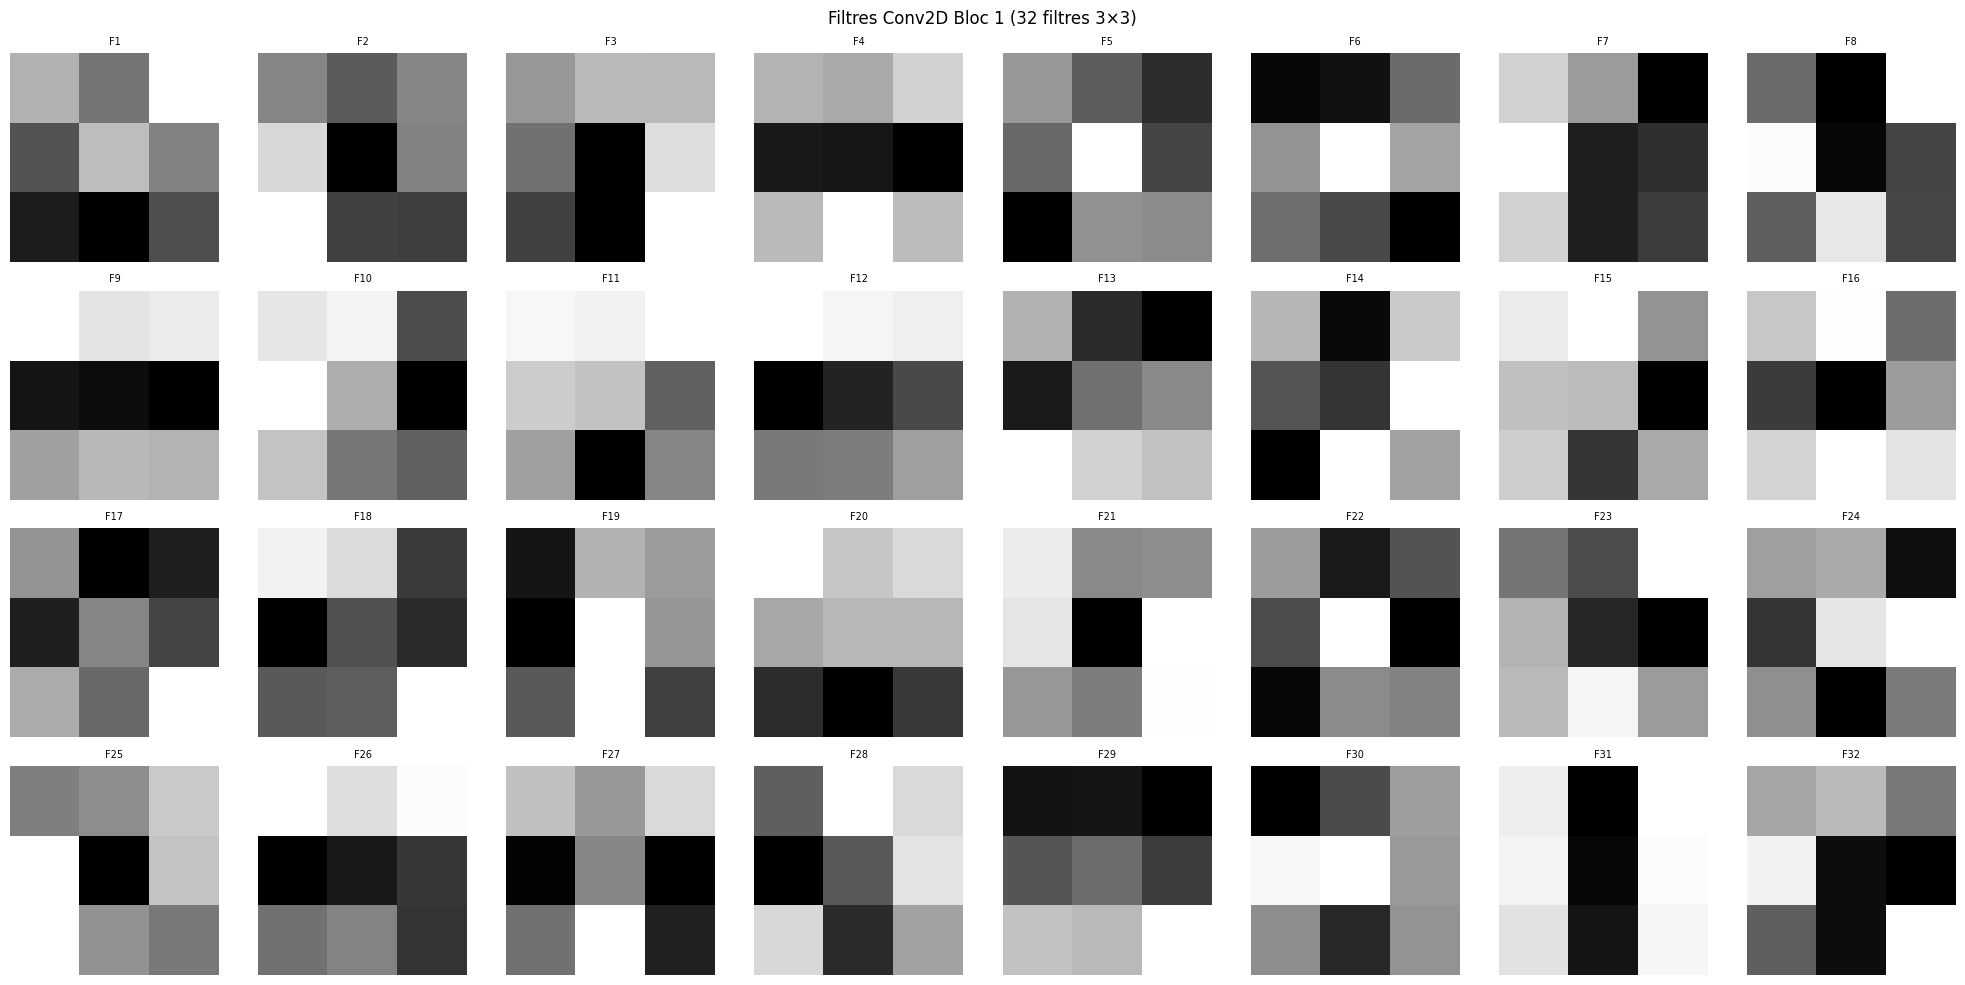

In [ ]:
import matplotlib.pyplot as plt

# Crée une figure de 20×10 pouces divisée en 4 lignes et 8 colonnes
# → 32 sous-figures pour afficher les 32 filtres du bloc 1
fig, axes = plt.subplots(4, 8, figsize=(20, 10))

# axes est un tableau 2D (4, 8) — axes.flat le convertit en itérateur 1D
# enumerate donne (0, ax0), (1, ax1), ... (31, ax31)
for i, ax in enumerate(axes.flat):

    # Extrait le filtre i : toutes les lignes, toutes les colonnes, canal 0
    # résultat : tableau 2D (3, 3) représentant la grille de valeurs du filtre
    ax.imshow(filters[:, :, 0, i], cmap='gray')

    # Désactive les axes (graduation, bordures) pour un affichage plus propre
    ax.axis('off')

    # Titre local de chaque sous-figure : F1, F2, ... F32
    ax.set_title(f'F{i+1}', fontsize=7)

# Titre global au-dessus de toute la figure
plt.suptitle('Filtres Conv2D Bloc 1 (32 filtres 3×3)')

# Ajuste automatiquement les espacements entre sous-figures
# pour éviter les chevauchements entre titres et images
plt.tight_layout()

plt.show()

In [ ]:
for i, layer in enumerate(model.layers):
    print(f"{i}  {layer.name}  {layer.__class__.__name__}")

0  conv2d  Conv2D
1  batch_normalization  BatchNormalization
2  activation  Activation
3  max_pooling2d  MaxPooling2D
4  dropout  Dropout
5  conv2d_1  Conv2D
6  batch_normalization_1  BatchNormalization
7  activation_1  Activation
8  max_pooling2d_1  MaxPooling2D
9  dropout_1  Dropout
10  conv2d_2  Conv2D
11  batch_normalization_2  BatchNormalization
12  activation_2  Activation
13  max_pooling2d_2  MaxPooling2D
14  dropout_2  Dropout
15  conv2d_3  Conv2D
16  batch_normalization_3  BatchNormalization
17  activation_3  Activation
18  max_pooling2d_3  MaxPooling2D
19  dropout_3  Dropout
20  flatten  Flatten
21  dense  Dense
22  batch_normalization_4  BatchNormalization
23  dropout_4  Dropout
24  dense_1  Dense


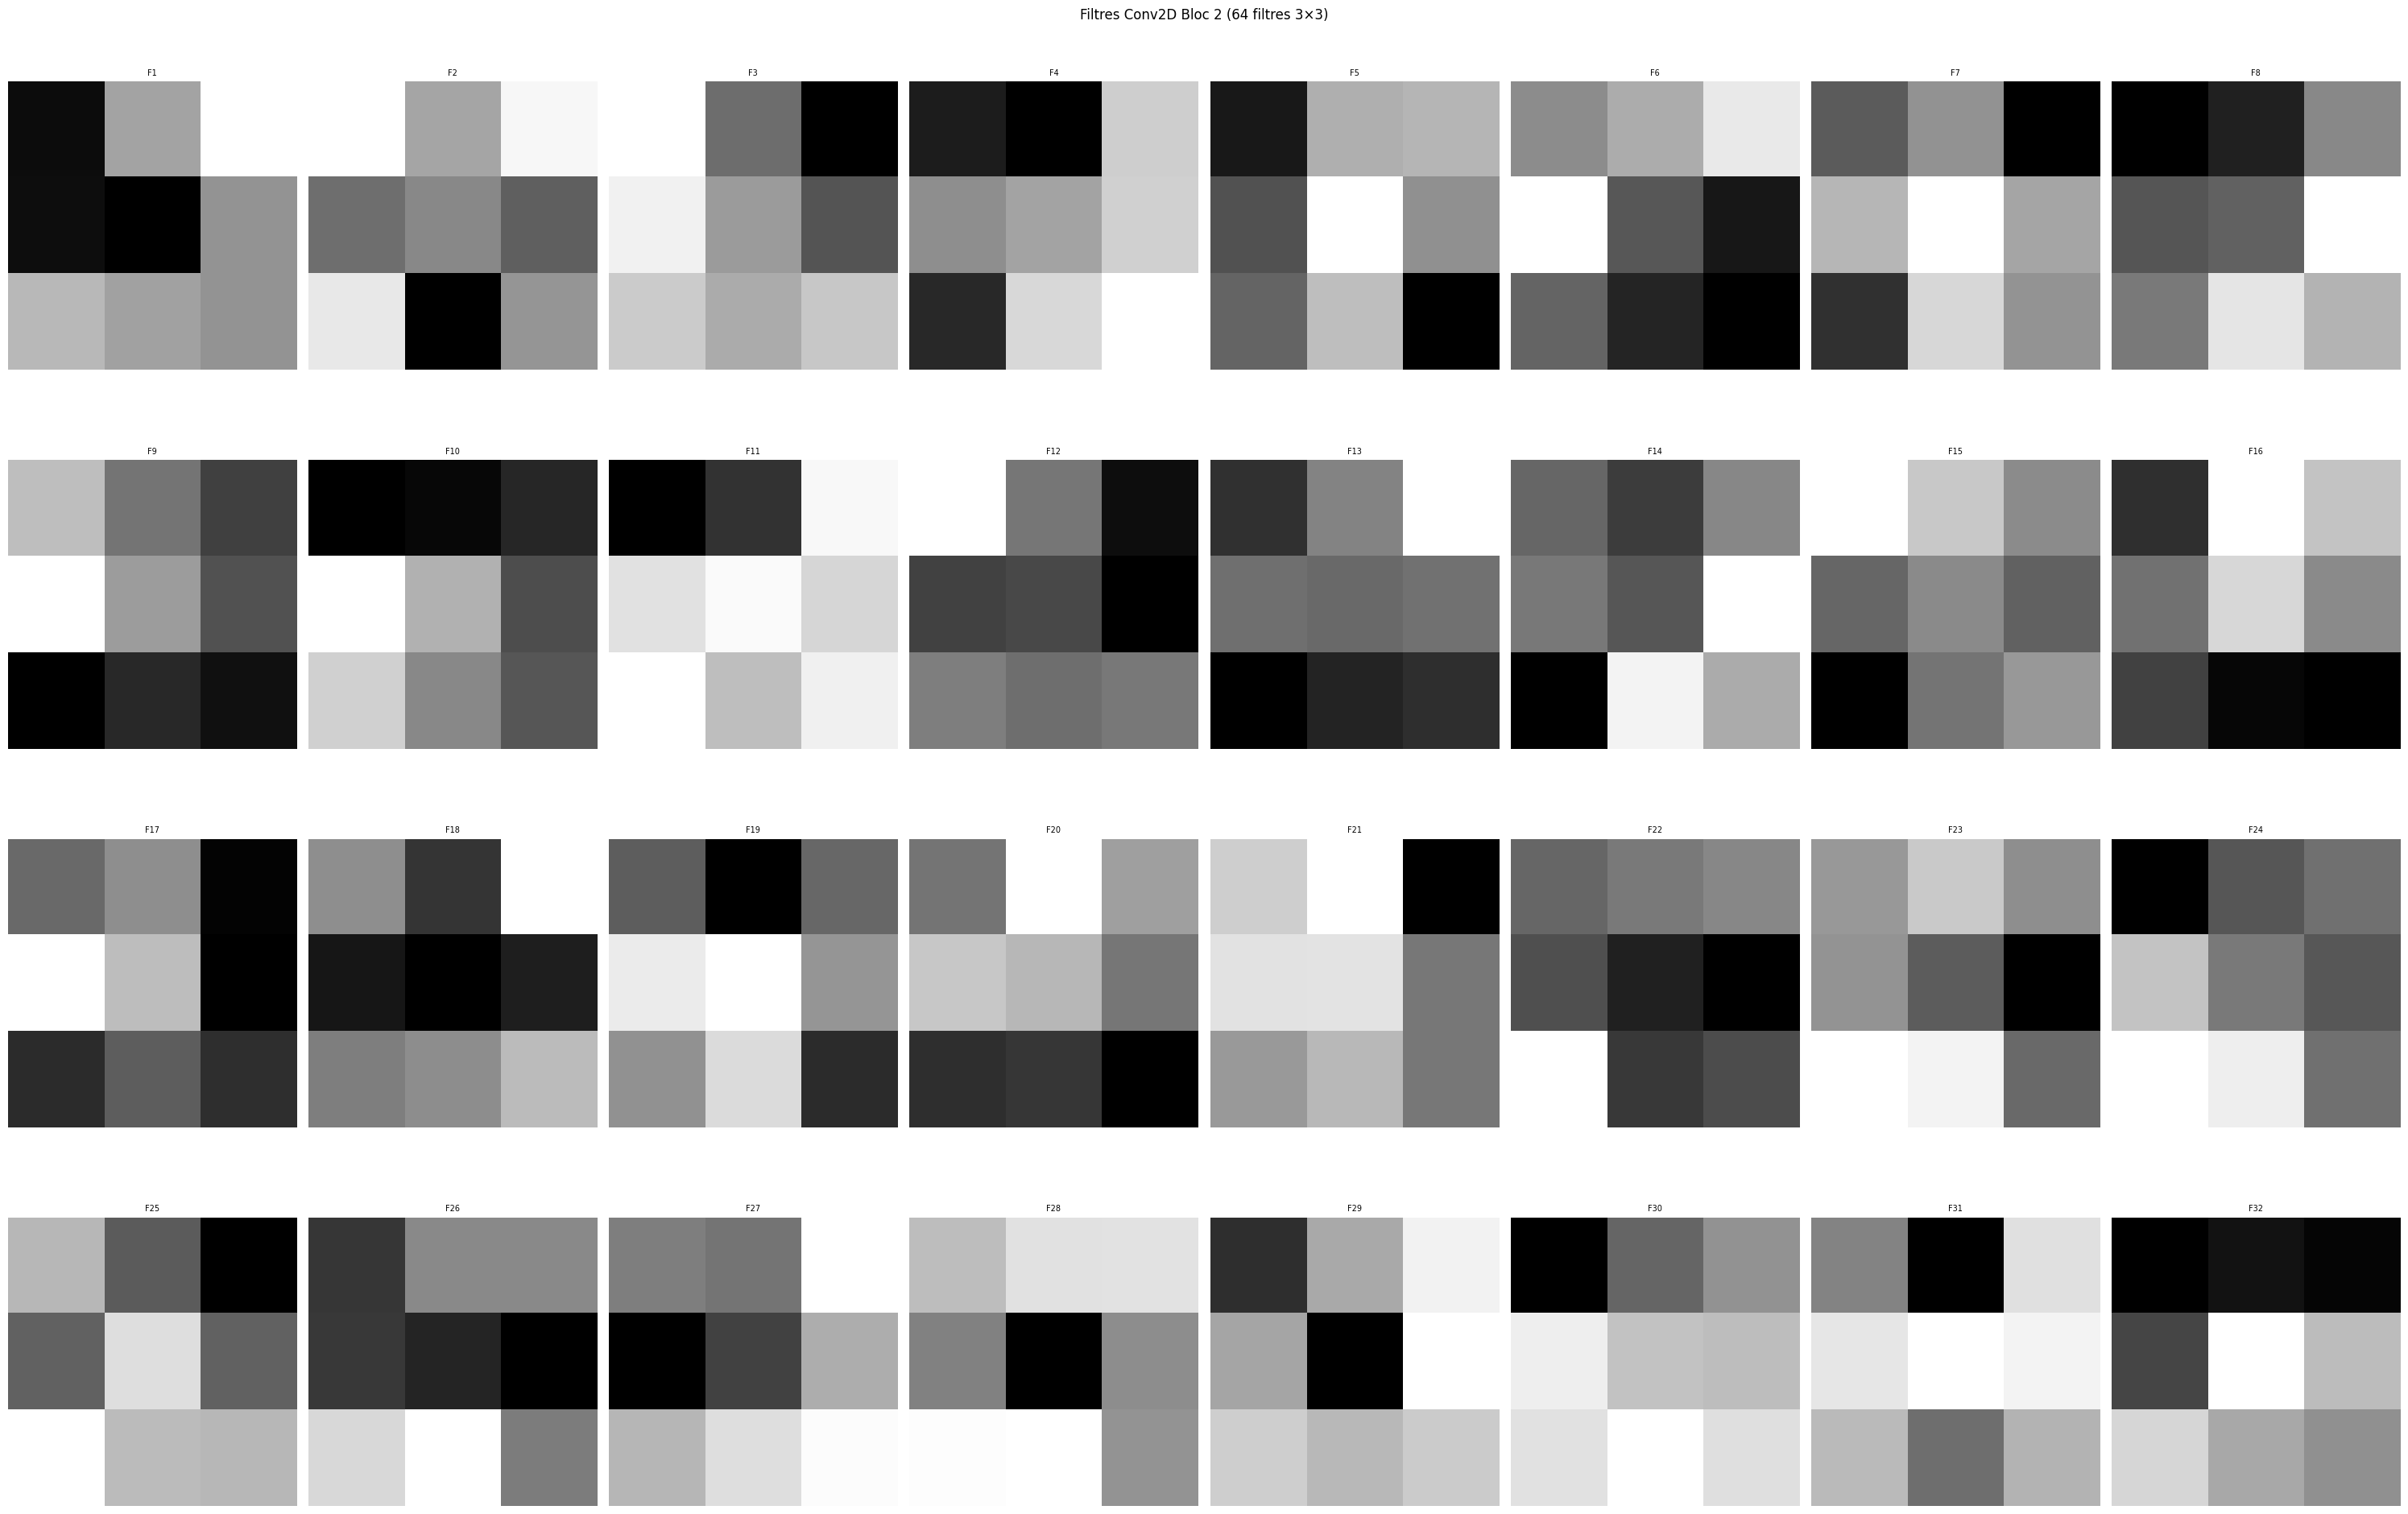

In [ ]:
layer = model.layers[5]
filters, biases = layer.get_weights()
fig, axes = plt.subplots(4,8, figsize=(30, 20))

for i, ax in enumerate(axes.flat):
    ax.imshow(filters[:, :, 0, i], cmap='gray')
    ax.axis('off')
    ax.set_title(f'F{i+1}', fontsize=7)

plt.suptitle('Filtres Conv2D Bloc 2 (64 filtres 3×3)')
plt.tight_layout()
plt.show()

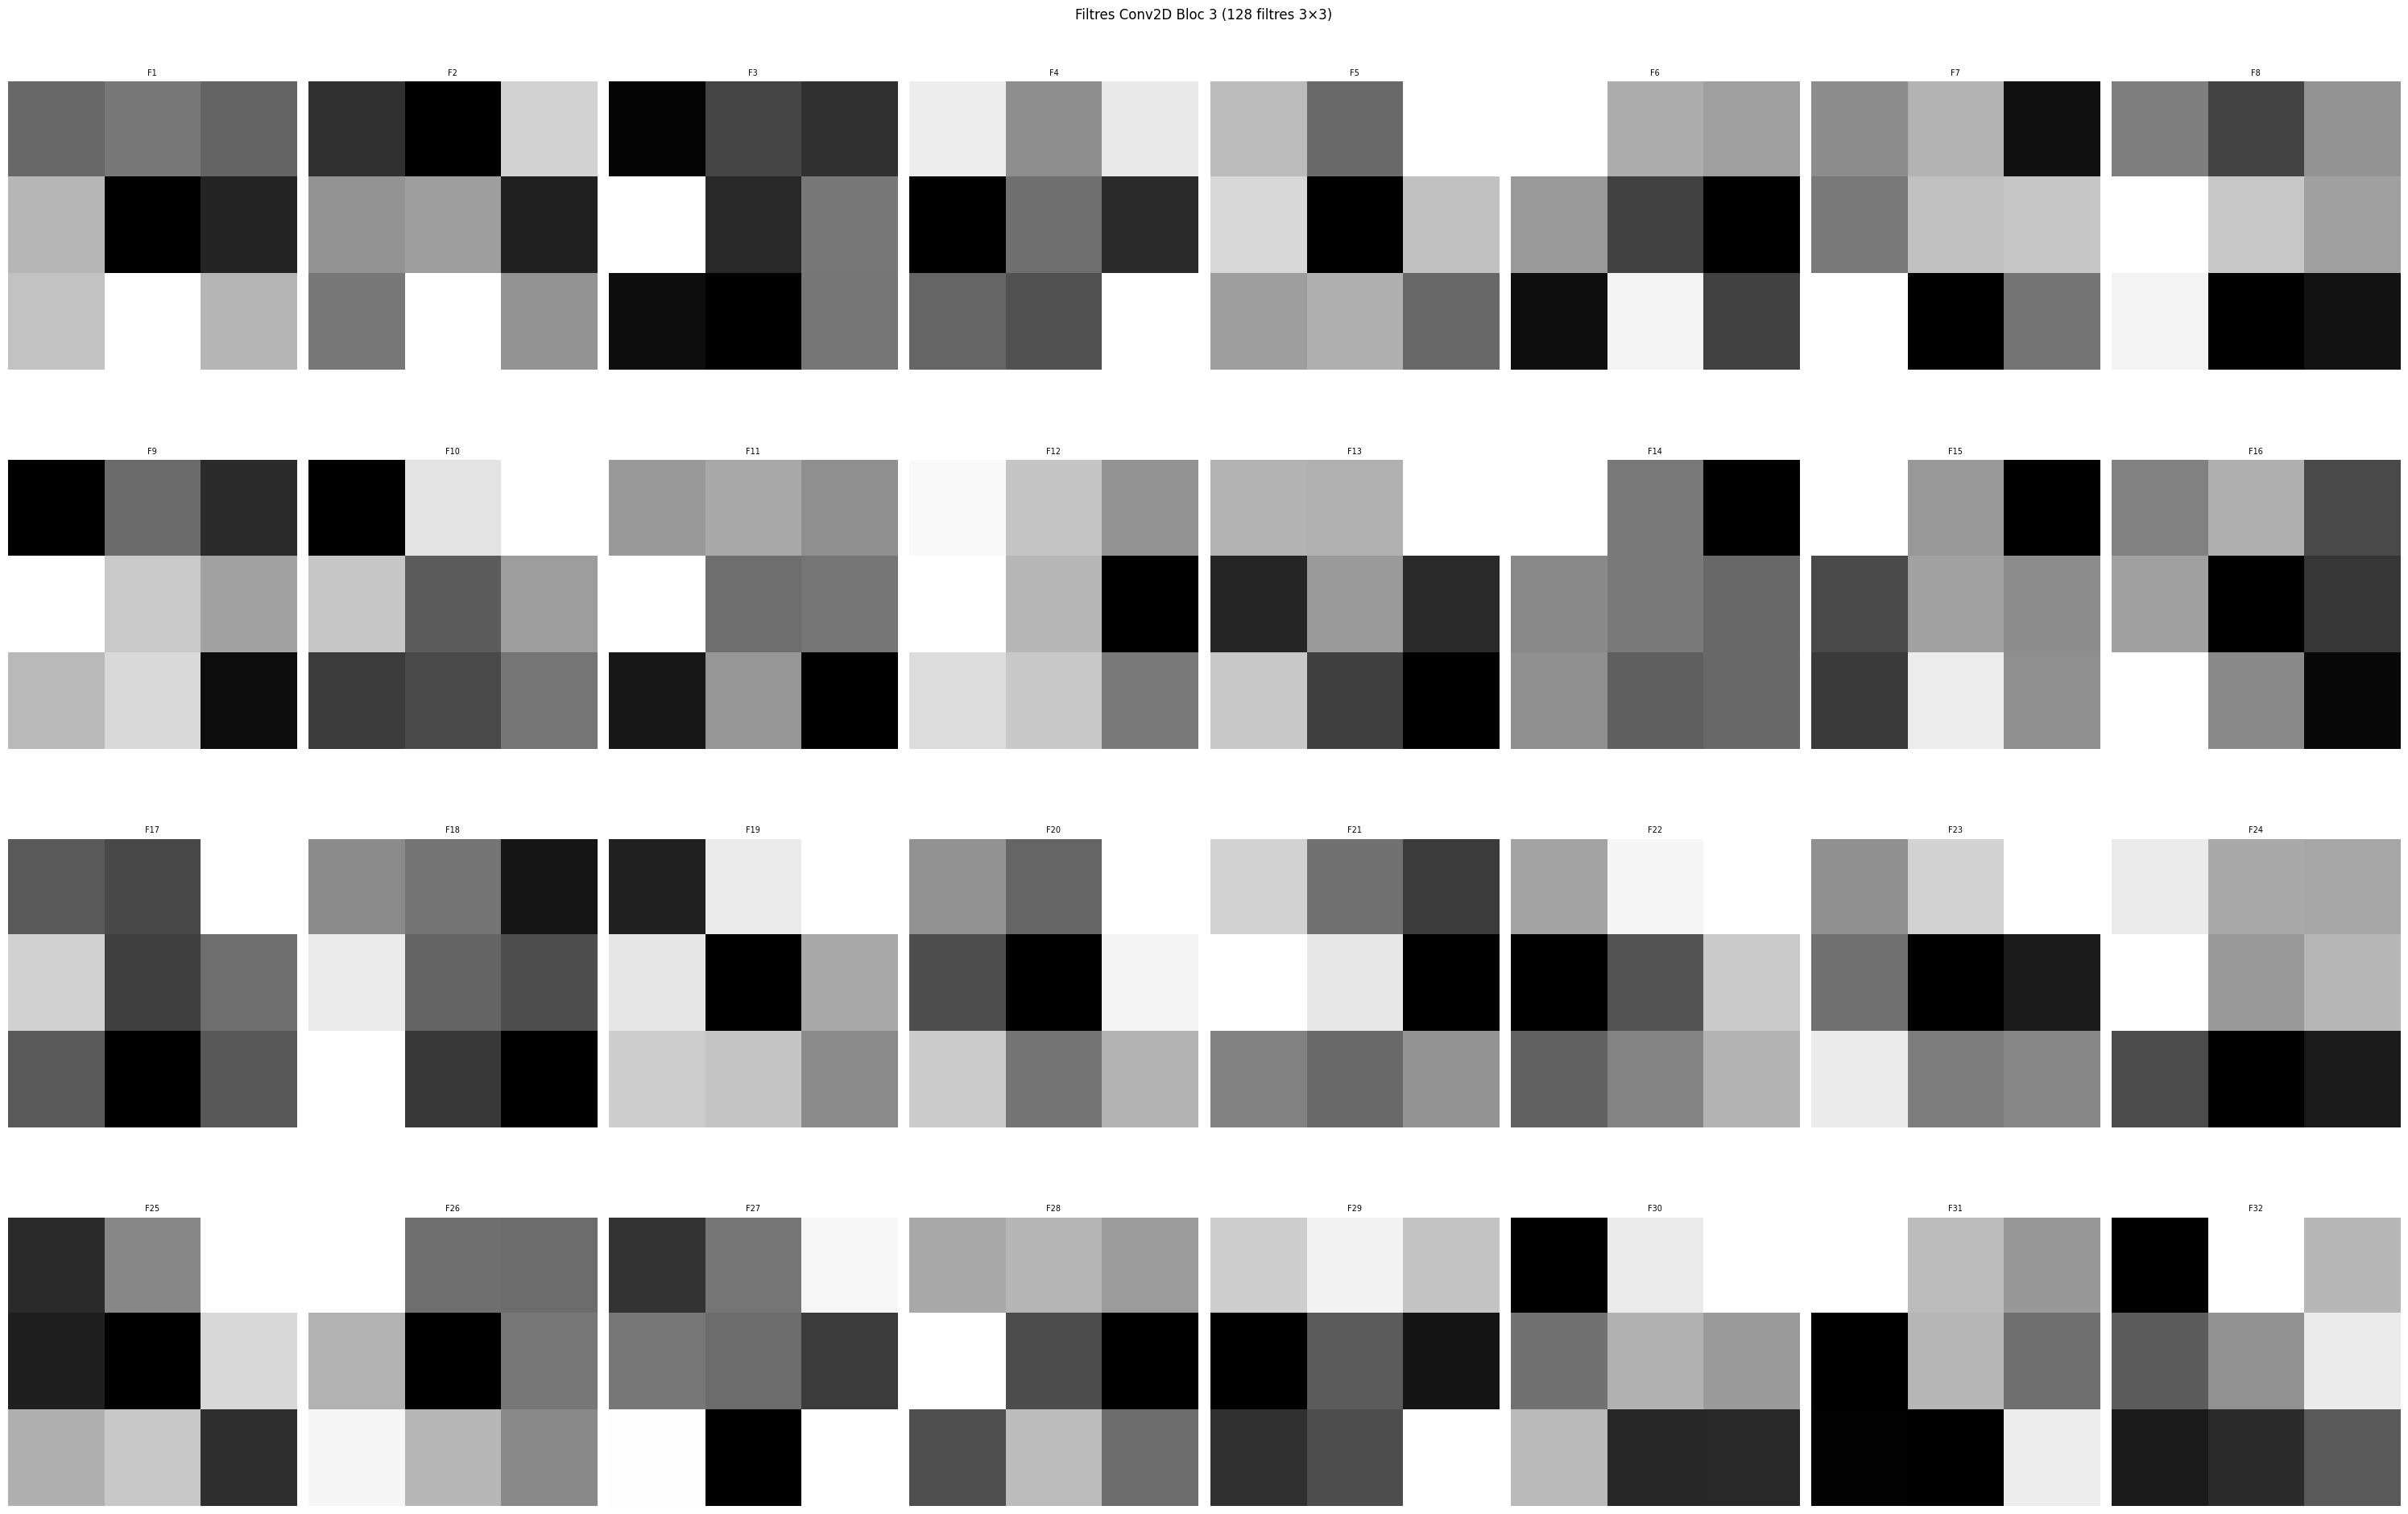

In [ ]:
layer = model.layers[10]
filters, biases = layer.get_weights()
fig, axes = plt.subplots(4, 8,  figsize=(30, 20))

for i, ax in enumerate(axes.flat):
    ax.imshow(filters[:, :, 0, i], cmap='gray')
    ax.axis('off')
    ax.set_title(f'F{i+1}', fontsize=7)

plt.suptitle('Filtres Conv2D Bloc 3 (128 filtres 3×3)')
plt.tight_layout()
plt.show()

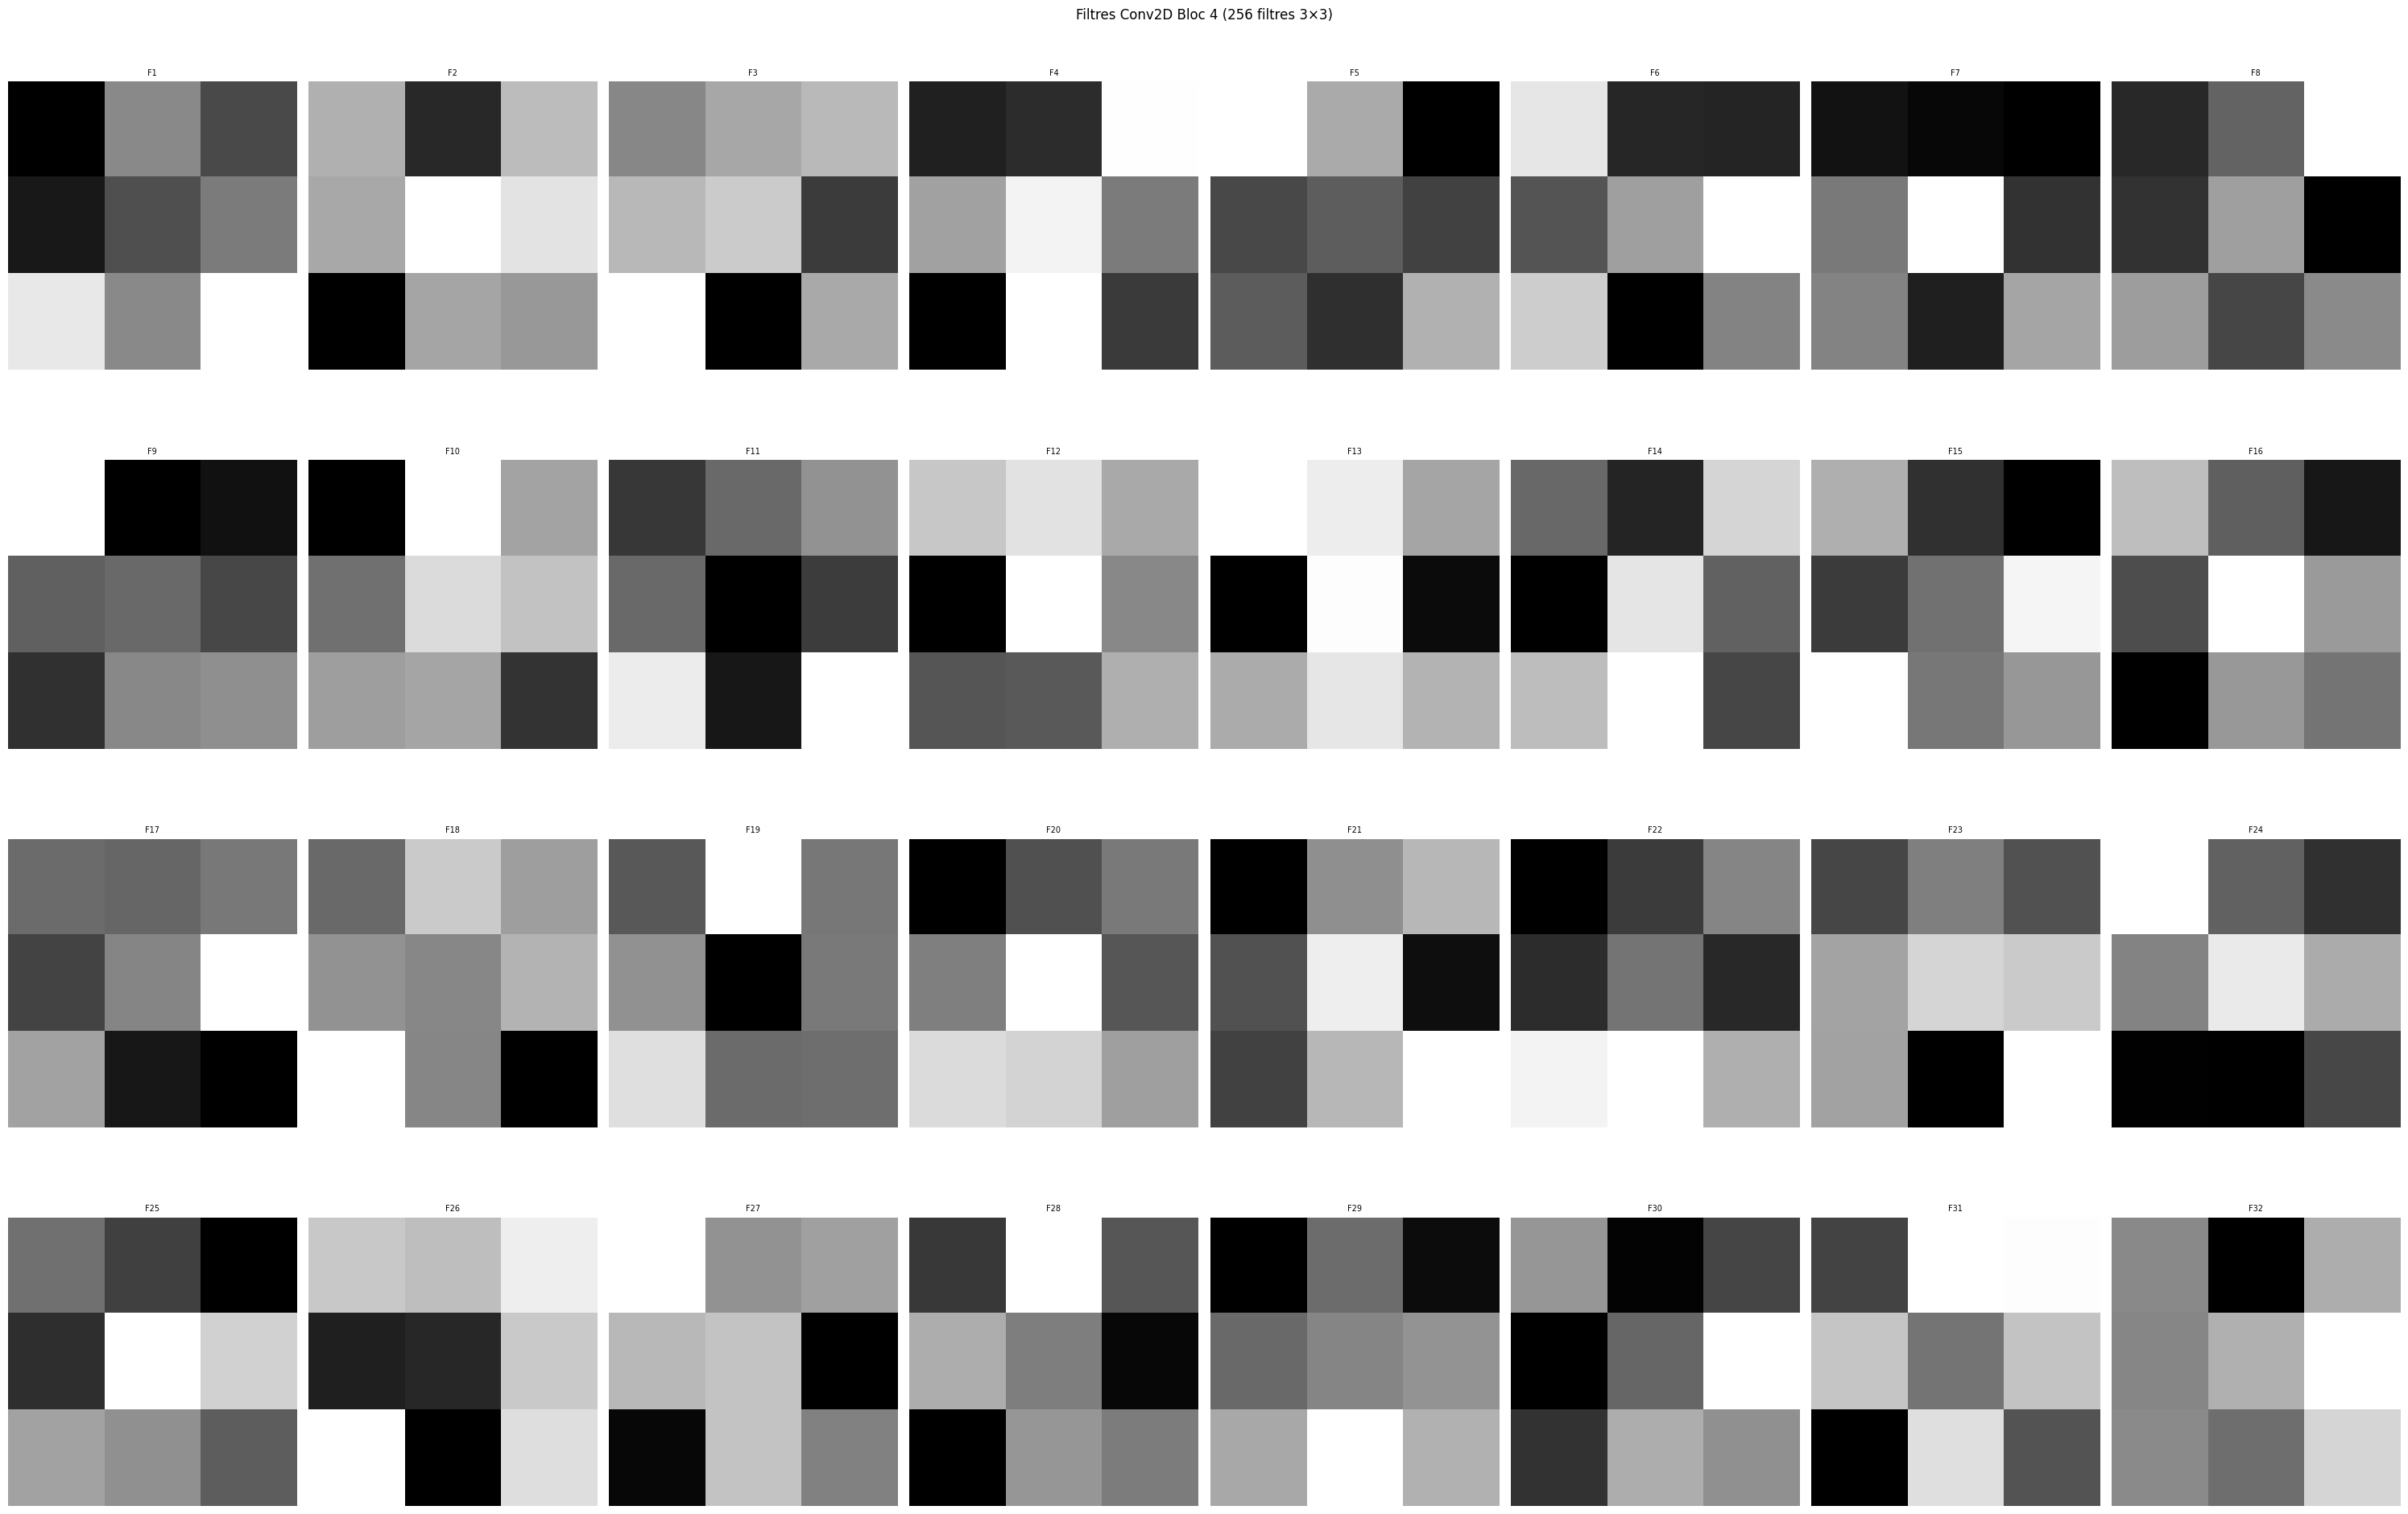

In [ ]:
layer = model.layers[15]
filters, biases = layer.get_weights()
fig, axes = plt.subplots(4, 8,  figsize=(30, 20))

for i, ax in enumerate(axes.flat):
    ax.imshow(filters[:, :, 0, i], cmap='gray')
    ax.axis('off')
    ax.set_title(f'F{i+1}', fontsize=7)

plt.suptitle('Filtres Conv2D Bloc 4 (256 filtres 3×3)')
plt.tight_layout()
plt.show()

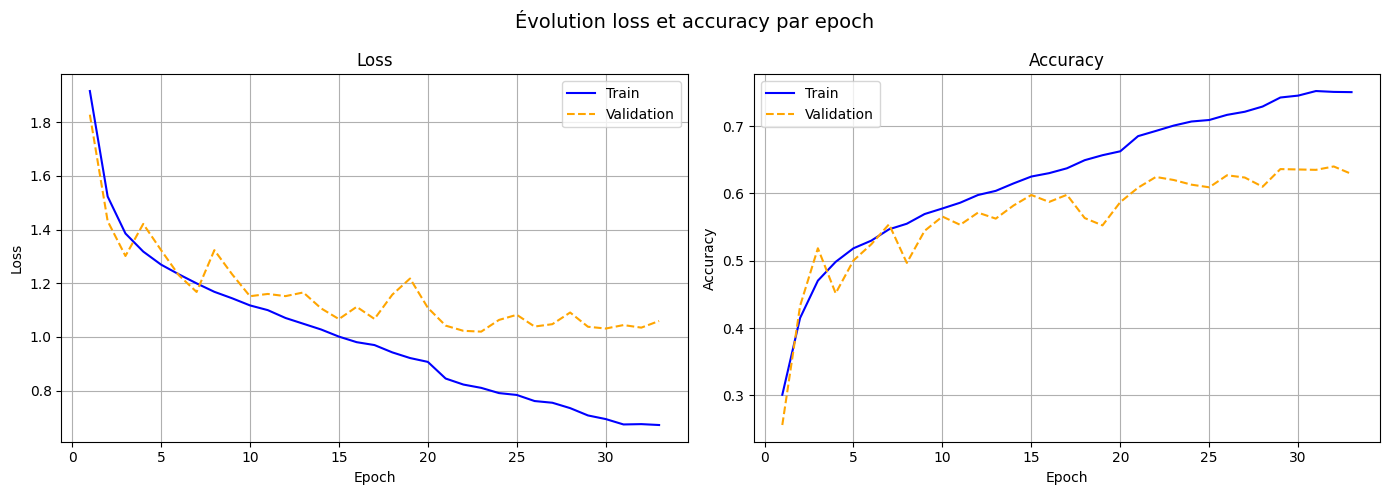

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

train_loss     = history.history['loss']
val_loss       = history.history['val_loss']
train_accuracy = history.history['accuracy']
val_accuracy   = history.history['val_accuracy']
epochs         = range(1, len(train_loss) + 1)

axes[0].plot(epochs, train_loss, label='Train',      color='blue')
axes[0].plot(epochs, val_loss,   label='Validation', color='orange', linestyle='--')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)


axes[1].plot(epochs, train_accuracy, label='Train',      color='blue')
axes[1].plot(epochs, val_accuracy,   label='Validation', color='orange', linestyle='--')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True)

plt.suptitle('Évolution loss et accuracy par epoch', fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
EMOTION_LABELS = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

In [ ]:
from sklearn.metrics import confusion_matrix
y_true = np.argmax(Y_test, axis=1)
y_pred = np.argmax(model.predict(X_test), axis=1)

cm = confusion_matrix(y_true, y_pred)


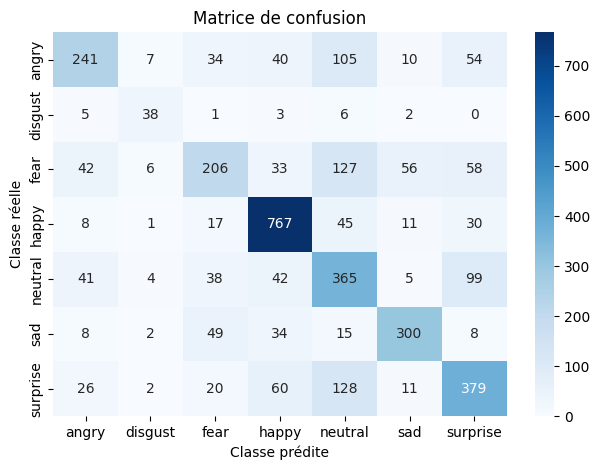

In [ ]:
import seaborn as sns

sns.heatmap(
    cm,
    annot=True,          # affiche les valeurs dans chaque cellule
    fmt='d',             # format entier
    cmap='Blues',        # palette de couleurs
    xticklabels=EMOTION_LABELS,
    yticklabels=EMOTION_LABELS
)
plt.title('Matrice de confusion')
plt.xlabel('Classe prédite')
plt.ylabel('Classe réelle')
plt.tight_layout()
plt.show()

In [ ]:
# Resauvegarder en format H5 (plus compatible)
model.save(os.path.join(base_path , 'models/best_model_fer2013.h5'))